# 🍷 Day 2: Exploratory Data Analysis & Physicochemical Feature Profiling
**Oasis Infobyte Data Analytics Internship — Task Level 2 (Task 2: Wine Quality Prediction)**

**Author:** Adarsh (Data Analytics Intern)  
**Date:** October 21, 2026  
**Dataset:** UCI Machine Learning Repository — Red Wine Quality (*Cortez et al., 2009*)  
**Tech Stack:** Python 3, Pandas, NumPy, Matplotlib, Seaborn, Scipy, Jupyter Notebook  

---

## 🎯 Objectives for Day 2
1. **Univariate Distribution Profiling:** Analyze central tendency, dispersion, skewness, and kurtosis across all 11 physicochemical measurements.
2. **Outlier Detection & Profiling:** Identify and quantify statistical outliers using Tukey's Interquartile Range (IQR) standard across each chemical attribute.
3. **Bivariate Quality Analysis:** Track how individual chemical properties shift across discrete sensory quality scores (scale 3–8).
4. **Correlation Matrix & Heatmap:** Compute full Pearson correlation matrix, generate an annotated correlation heatmap, and rank key drivers.
5. **Multicollinearity Assessment:** Pinpoint inter-feature relationships (e.g. fixed acidity vs. density, citric acid, pH; free vs. total sulfur dioxide).
6. **In-Depth Class Imbalance Discussion:** Rigorously evaluate how underrepresented classes affect loss functions, gradient updates, and classifier performance, establishing the statistical foundation for stratified sampling, cost-sensitive learning, and target binning.

In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Plotting configuration
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
sns.set_theme(style='whitegrid', palette='muted')

# Define repository directories
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name.lower() == 'notebooks' else NOTEBOOK_DIR
DATA_PATH = PROJECT_ROOT / 'Data' / 'winequality-red.csv'
FIG_DIR = PROJECT_ROOT / 'reports' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

print(f'Working directory: {PROJECT_ROOT}')
print(f'Data location: {DATA_PATH.resolve()}')

Working directory: C:\Users\Iba Zaidi\Desktop\OIBSIP\DataAnalytics-L2-WineQuality
Data location: C:\Users\Iba Zaidi\Desktop\OIBSIP\DataAnalytics-L2-WineQuality\Data\winequality-red.csv


## 1. Data Ingestion & Schema Inspection
We load the red wine dataset from `Data/winequality-red.csv` and verify record completeness.

In [2]:
df = pd.read_csv(DATA_PATH, sep=';')
print(f'Dimensions: {df.shape[0]} rows × {df.shape[1]} columns')
print(f'Total Missing Values: {df.isnull().sum().sum()}')
df.head()

Dimensions: 1599 rows × 12 columns
Total Missing Values: 0


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## 2. Comprehensive Statistical Profiling
We compute detailed descriptive statistics including central tendency (mean, median), dispersion (std, IQR), and shape metrics (skewness, kurtosis).

In [3]:
features = [c for c in df.columns if c != 'quality']
stats_list = []

for col in features:
    s = df[col]
    q25 = s.quantile(0.25)
    q75 = s.quantile(0.75)
    stats_list.append({
        'Feature': col,
        'Mean': round(s.mean(), 3),
        'Std': round(s.std(), 3),
        'Median': round(s.median(), 3),
        'IQR': round(q75 - q25, 3),
        'Min': round(s.min(), 3),
        'Max': round(s.max(), 3),
        'Skewness': round(s.skew(), 3),
        'Kurtosis': round(s.kurt(), 3)
    })

df_stats = pd.DataFrame(stats_list)
display(df_stats)

,Feature,Mean,Std,Median,IQR,Min,Max,Skewness,Kurtosis
0,fixed acidity,8.320,1.741,7.900,2.100,4.600,15.900,0.983,1.132
1,volatile acidity,0.528,0.179,0.520,0.250,0.120,1.580,0.672,1.226
2,citric acid,0.271,0.195,0.260,0.330,0.000,1.000,0.318,-0.789
3,residual sugar,2.539,1.410,2.200,0.700,0.900,15.500,4.541,28.618
4,chlorides,0.087,0.047,0.079,0.020,0.012,0.611,5.680,41.716
5,free sulfur dioxide,15.875,10.460,14.000,14.000,1.000,72.000,1.251,2.024
6,total sulfur dioxide,46.468,32.895,38.000,40.000,6.000,289.000,1.516,3.810
7,density,0.997,0.002,0.997,0.002,0.990,1.004,0.071,0.934
8,pH,3.311,0.154,3.310,0.190,2.740,4.010,0.194,0.807
9,sulphates,0.658,0.170,0.620,0.180,0.330,2.000,2.429,11.720


## 3. Univariate Distributions (Histograms & KDE)
Visualizing individual feature densities reveals parametric properties and distributional skewness:
- `alcohol`, `fixed acidity`, `sulphates`, `volatile acidity` display moderate positive skewness.
- `residual sugar`, `chlorides`, `free sulfur dioxide`, `total sulfur dioxide` exhibit extreme positive skewness with elongated right-hand tails.
- `density` and `pH` display remarkably symmetrical, near-Gaussian bell-shaped distributions.

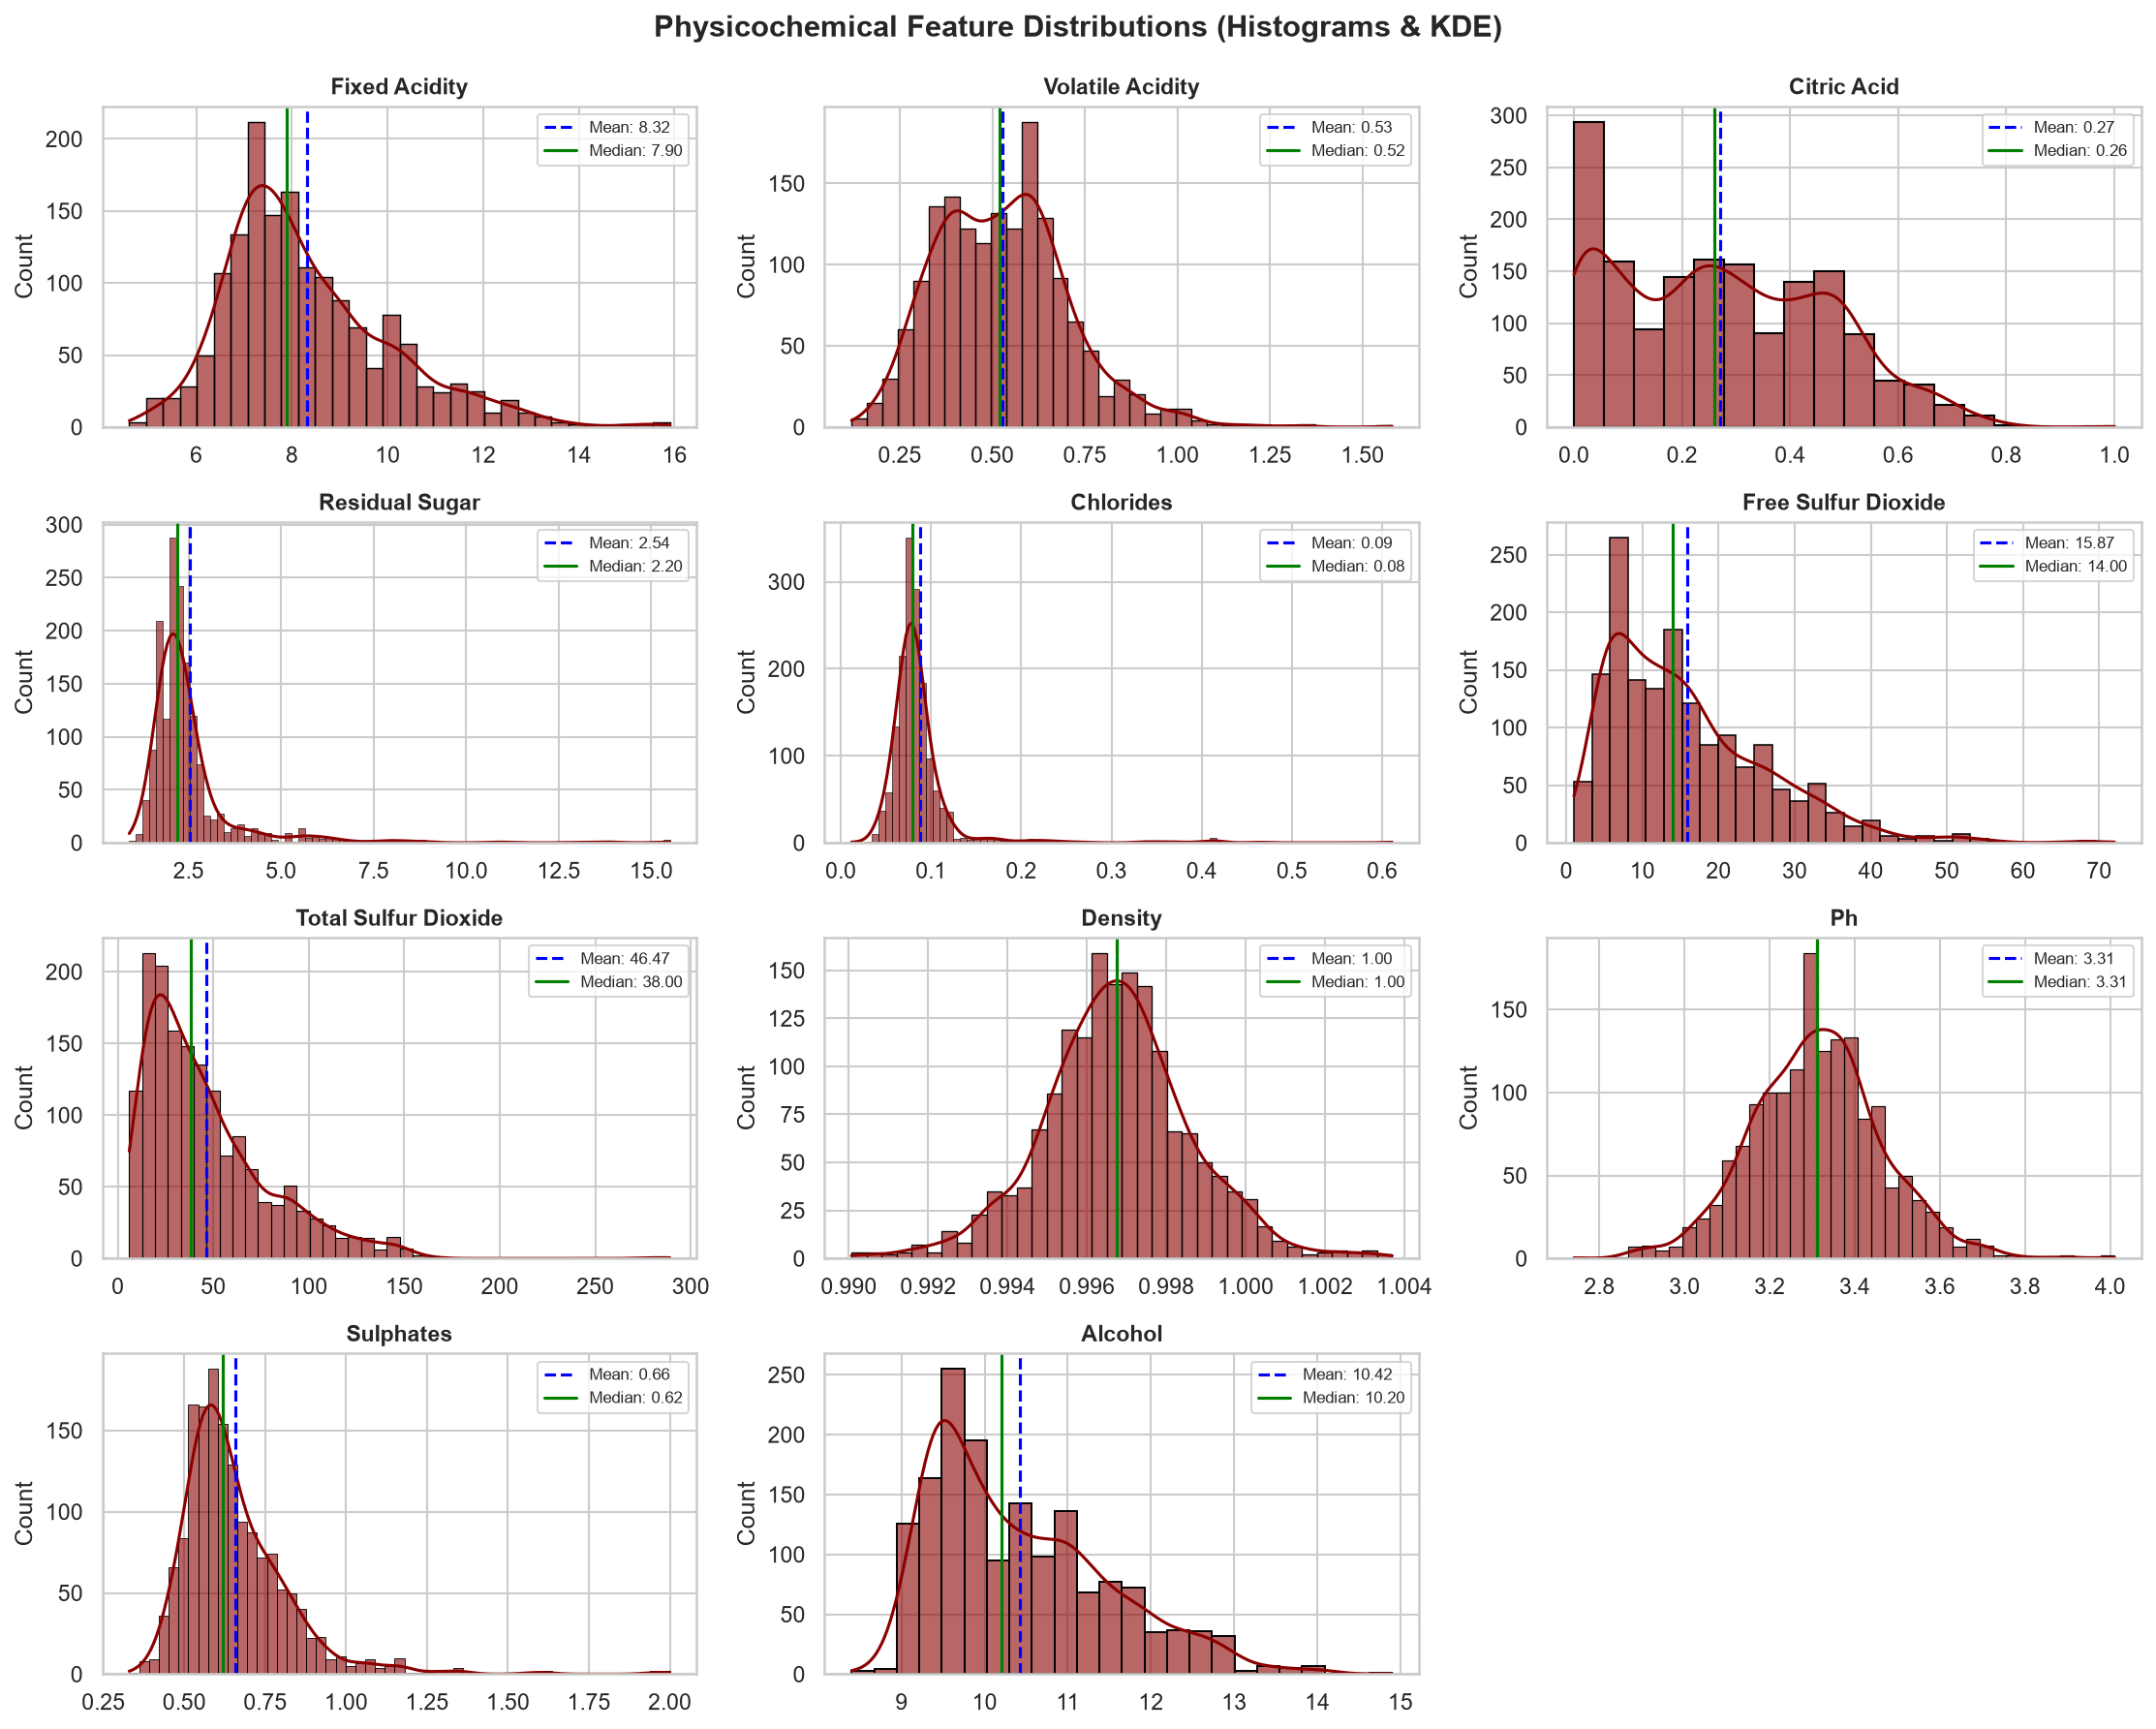

In [4]:
fig, axes = plt.subplots(4, 3, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(features):
    ax = axes[i]
    sns.histplot(df[col], kde=True, ax=ax, color='#8B0000', edgecolor='black', alpha=0.6)
    mean_val = df[col].mean()
    median_val = df[col].median()
    ax.axvline(mean_val, color='blue', linestyle='--', linewidth=1.5, label=f'Mean: {mean_val:.2f}')
    ax.axvline(median_val, color='green', linestyle='-', linewidth=1.5, label=f'Median: {median_val:.2f}')
    ax.set_title(f'{col.title()}', fontsize=11, fontweight='bold')
    ax.set_xlabel('')
    ax.legend(fontsize=8, loc='upper right')

# Hide 12th unused subplot
fig.delaxes(axes[11])

plt.suptitle('Physicochemical Feature Distributions (Histograms & KDE)', fontsize=15, fontweight='bold', y=0.99)
plt.tight_layout()
plt.savefig(FIG_DIR / 'day2_univariate_distributions.png', bbox_inches='tight')
plt.show()

## 4. Outlier Profiling via Tukey's IQR Method
Using the standard rule:
$$\text{Lower Bound} = Q_1 - 1.5 \times \text{IQR}, \quad \text{Upper Bound} = Q_3 + 1.5 \times \text{IQR}$$
We identify observations lying outside the interquartile fences.

In [5]:
outlier_rows = []
for col in features:
    s = df[col]
    q25 = s.quantile(0.25)
    q75 = s.quantile(0.75)
    iqr = q75 - q25
    lower = q25 - 1.5 * iqr
    upper = q75 + 1.5 * iqr
    count = ((s < lower) | (s > upper)).sum()
    pct = (count / len(df)) * 100.0
    outlier_rows.append({
        'Feature': col,
        'Lower Fence': round(lower, 3),
        'Upper Fence': round(upper, 3),
        'Outlier Count': count,
        'Outlier Share (%)': round(pct, 2)
    })

df_outliers = pd.DataFrame(outlier_rows).sort_values(by='Outlier Count', ascending=False).reset_index(drop=True)
display(df_outliers)

,Feature,Lower Fence,Upper Fence,Outlier Count,Outlier Share (%)
0,residual sugar,0.850,3.650,155,9.69
1,chlorides,0.040,0.120,112,7.00
2,sulphates,0.280,1.000,59,3.69
3,total sulfur dioxide,-38.000,122.000,55,3.44
4,fixed acidity,3.950,12.350,49,3.06
5,density,0.992,1.001,45,2.81
6,pH,2.925,3.685,35,2.19
7,free sulfur dioxide,-14.000,42.000,30,1.88
8,volatile acidity,0.015,1.015,19,1.19
9,alcohol,7.100,13.500,13,0.81


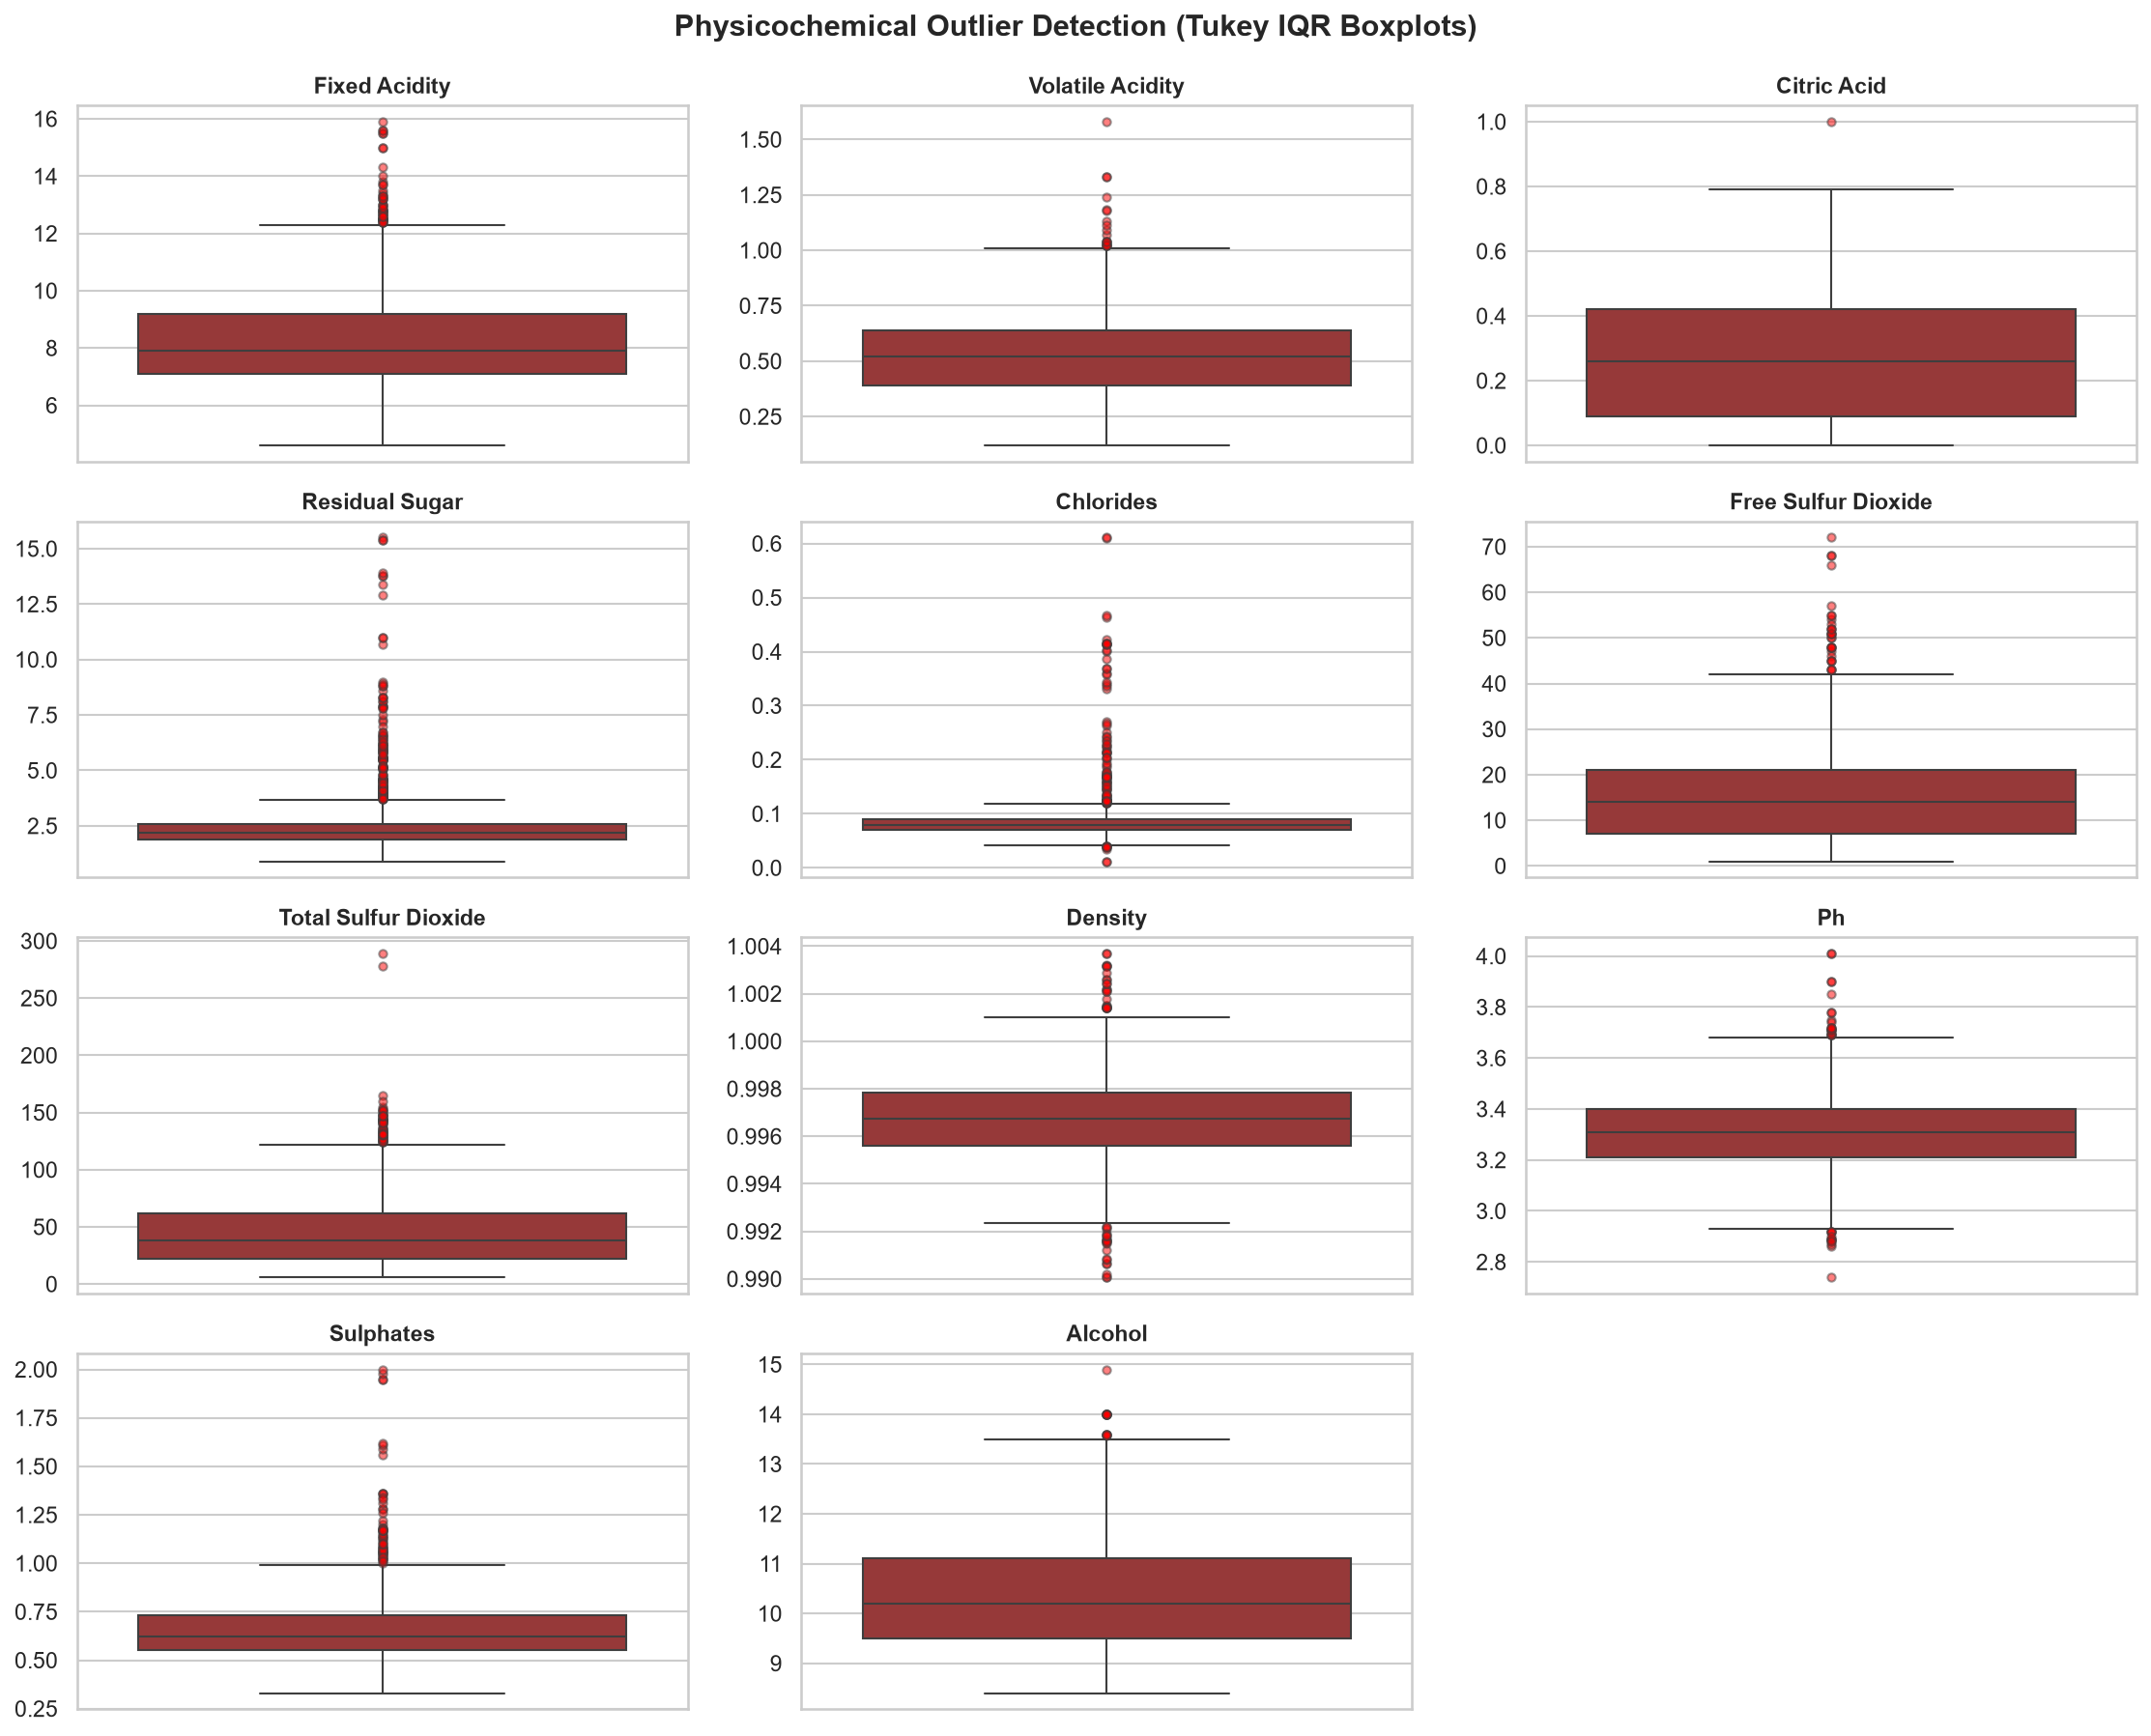

In [6]:
fig, axes = plt.subplots(4, 3, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(features):
    ax = axes[i]
    sns.boxplot(y=df[col], ax=ax, color='#A52A2A', flierprops=dict(marker='o', markersize=4, markerfacecolor='red', alpha=0.5))
    ax.set_title(f'{col.title()}', fontsize=11, fontweight='bold')
    ax.set_ylabel('')

fig.delaxes(axes[11])
plt.suptitle('Physicochemical Outlier Detection (Tukey IQR Boxplots)', fontsize=15, fontweight='bold', y=0.99)
plt.tight_layout()
plt.savefig(FIG_DIR / 'day2_feature_boxplots.png', bbox_inches='tight')
plt.show()

## 5. Bivariate Feature Analysis Across Wine Quality (Scores 3–8)
We track how chemical profiles systematically vary between low-grade and high-grade wines.

C:\Users\Iba Zaidi\AppData\Local\Temp\ipykernel_13924\1929905053.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='quality', y=col, data=df, ax=ax, palette='Reds')
C:\Users\Iba Zaidi\AppData\Local\Temp\ipykernel_13924\1929905053.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='quality', y=col, data=df, ax=ax, palette='Reds')


C:\Users\Iba Zaidi\AppData\Local\Temp\ipykernel_13924\1929905053.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='quality', y=col, data=df, ax=ax, palette='Reds')


C:\Users\Iba Zaidi\AppData\Local\Temp\ipykernel_13924\1929905053.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='quality', y=col, data=df, ax=ax, palette='Reds')


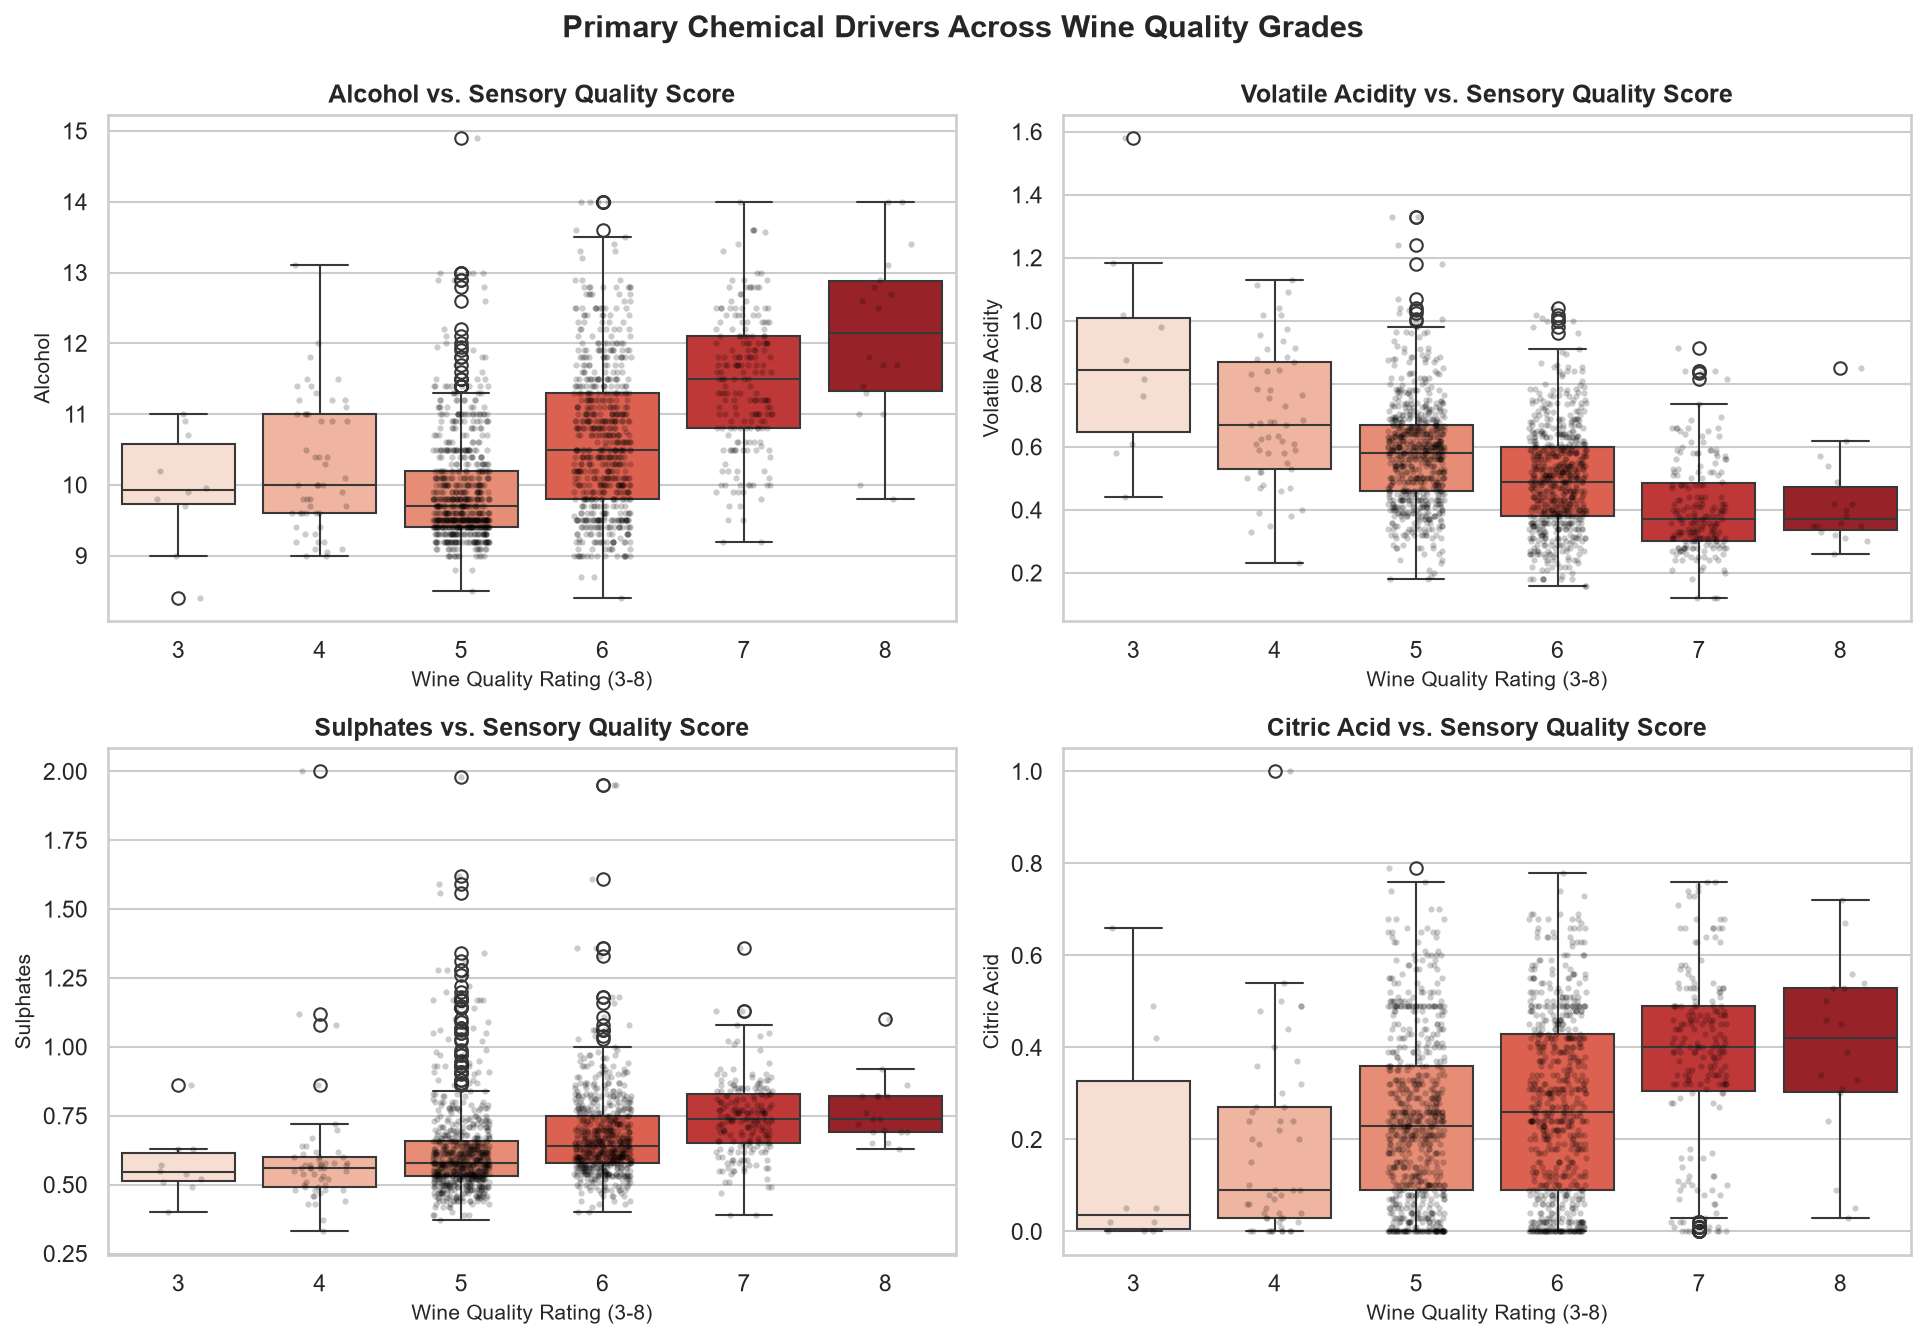

In [7]:
key_drivers = ['alcohol', 'volatile acidity', 'sulphates', 'citric acid']
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.flatten()

for i, col in enumerate(key_drivers):
    ax = axes[i]
    sns.boxplot(x='quality', y=col, data=df, ax=ax, palette='Reds')
    sns.stripplot(x='quality', y=col, data=df, ax=ax, color='black', alpha=0.2, jitter=0.2, size=3)
    ax.set_title(f'{col.title()} vs. Sensory Quality Score', fontsize=12, fontweight='bold')
    ax.set_xlabel('Wine Quality Rating (3-8)', fontsize=10)
    ax.set_ylabel(col.title(), fontsize=10)

plt.suptitle('Primary Chemical Drivers Across Wine Quality Grades', fontsize=15, fontweight='bold', y=0.99)
plt.tight_layout()
plt.savefig(FIG_DIR / 'day2_features_vs_quality.png', bbox_inches='tight')
plt.show()

## 6. Correlation Analysis & Multicollinearity Diagnostics
We compute the Pearson linear correlation matrix across all 12 attributes.

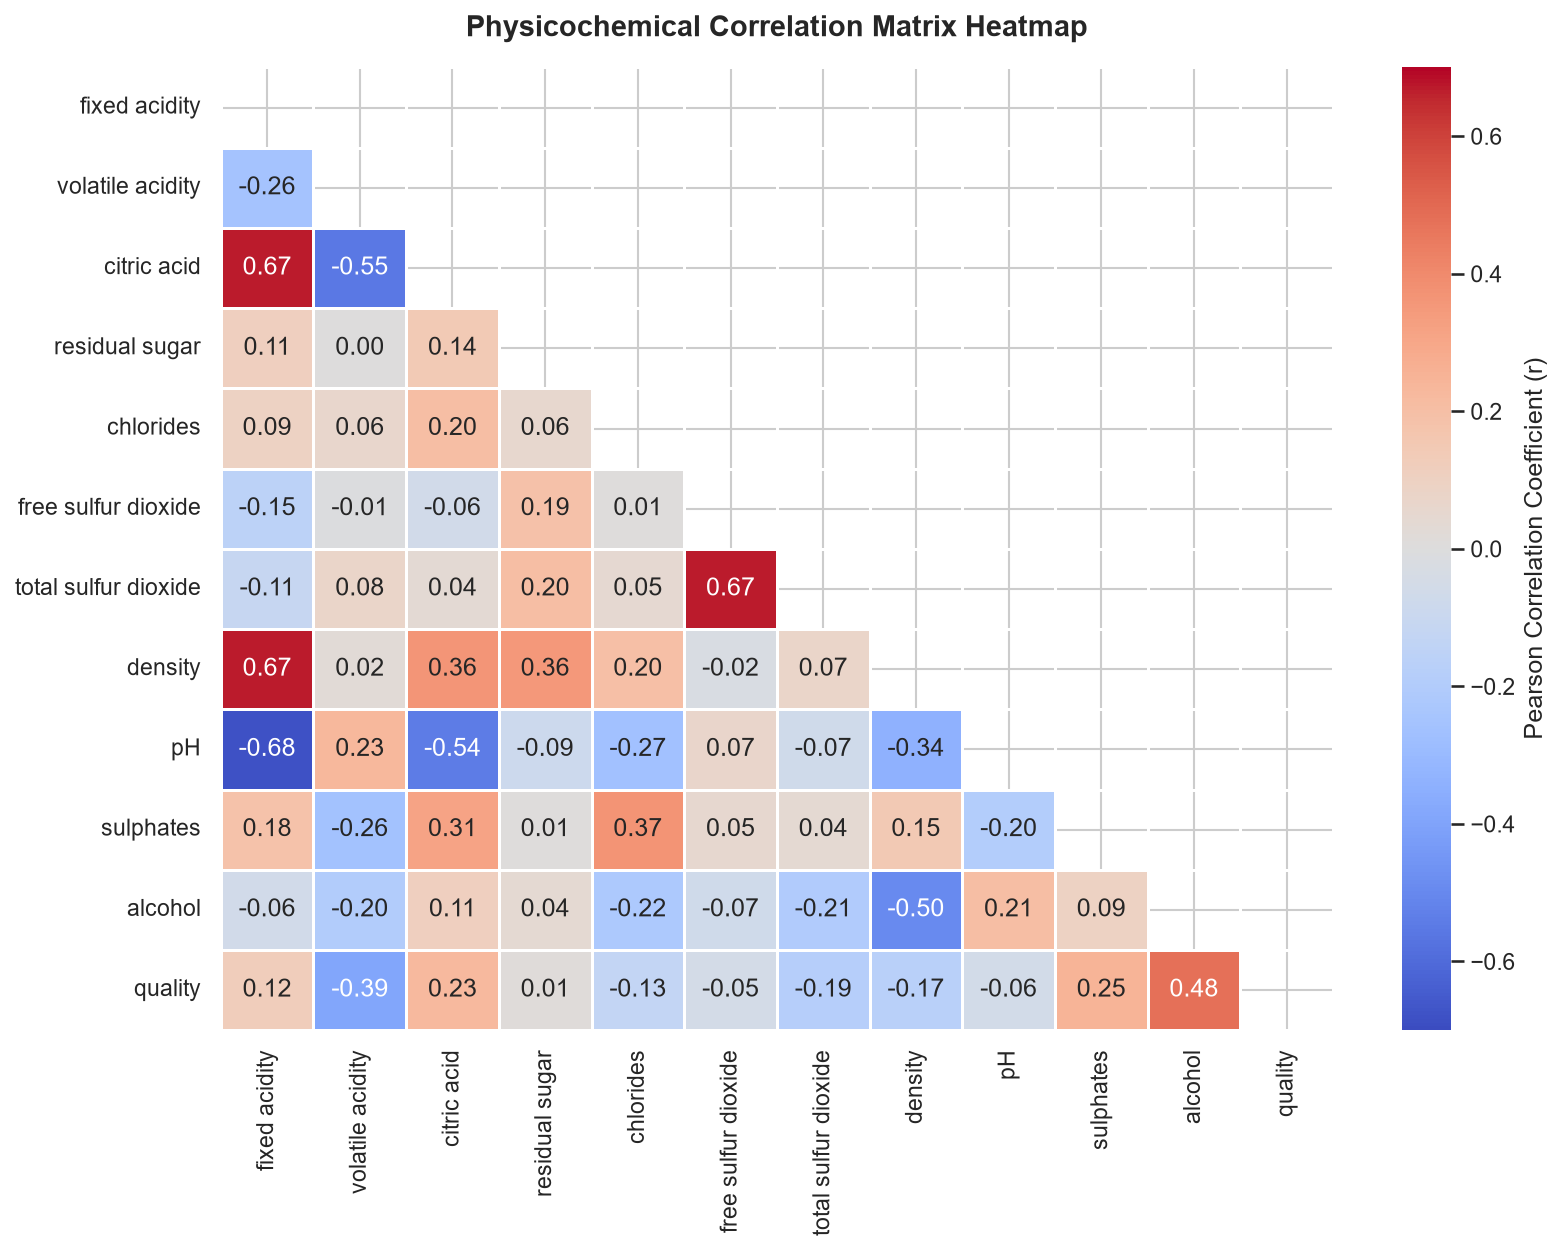

In [8]:
corr_matrix = df.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(11, 8.5))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-0.7,
    vmax=0.7,
    linewidths=0.5,
    cbar_kws={'label': 'Pearson Correlation Coefficient (r)'}
)
plt.title('Physicochemical Correlation Matrix Heatmap', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig(FIG_DIR / 'day2_correlation_heatmap.png', bbox_inches='tight')
plt.show()

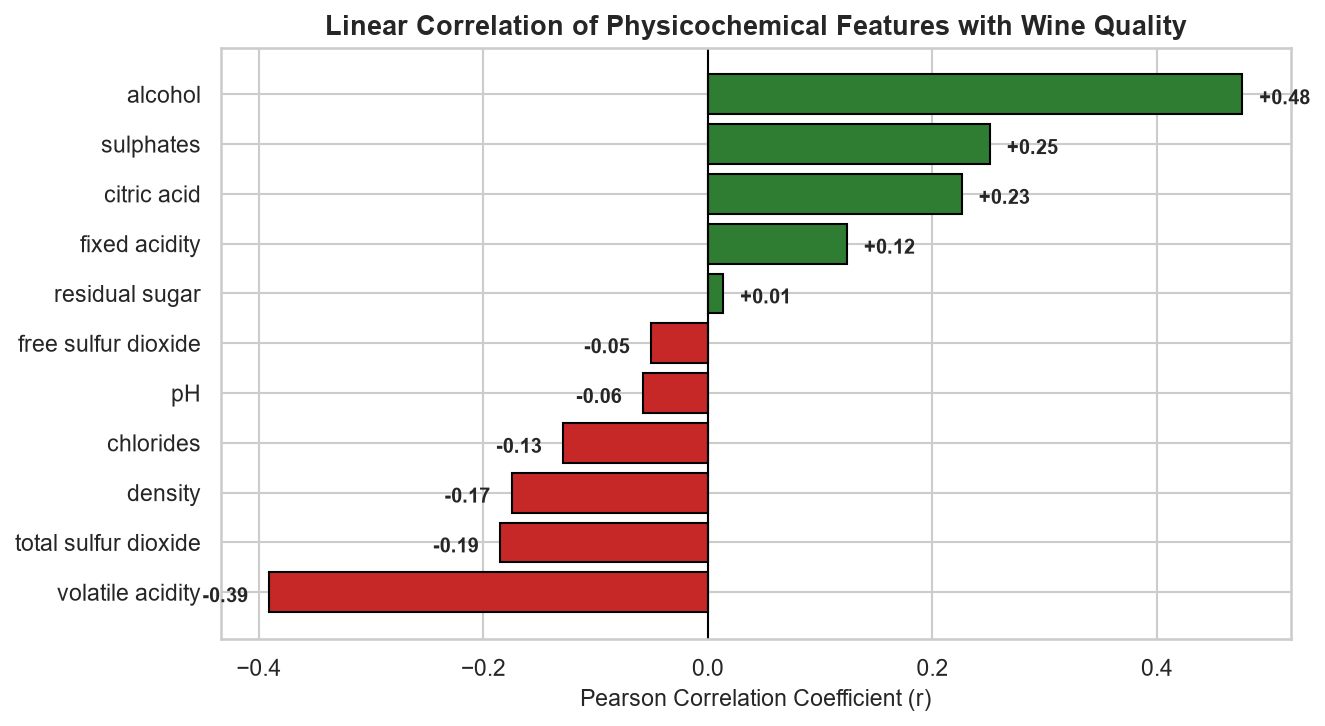

In [9]:
target_corr = corr_matrix['quality'].drop('quality').sort_values()

plt.figure(figsize=(9, 5))
colors = ['#2E7D32' if v > 0 else '#C62828' for v in target_corr]
bars = plt.barh(target_corr.index, target_corr.values, color=colors, edgecolor='black')
plt.axvline(0, color='black', linewidth=1)
plt.title('Linear Correlation of Physicochemical Features with Wine Quality', fontsize=13, fontweight='bold')
plt.xlabel('Pearson Correlation Coefficient (r)', fontsize=11)

# Label values on bars
for bar in bars:
    w = bar.get_width()
    offset = 0.015 if w >= 0 else -0.06
    plt.text(w + offset, bar.get_y() + bar.get_height()/4, f'{w:+.2f}', fontsize=9.5, fontweight='bold')

plt.tight_layout()
plt.savefig(FIG_DIR / 'day2_top_correlations.png', bbox_inches='tight')
plt.show()

## 7. In-Depth Discussion: Class Imbalance & Modeling Implications

### 1. Quantification of Severe Imbalance
In Day 1 and Day 2 inspection, the discrete sensory quality score exhibits extreme non-uniformity:
- **Middle-Tier Dominance:** Scores **5** (42.59%) and **6** (39.90%) account for **82.49% (1,319 / 1,599)** of all samples.
- **Minority Polarization:** Scores **3** ($N=10$, 0.63%) and **8** ($N=18$, 1.13%) represent rare enological extremes.
- **Commercial Reserve Group:** Scores $\ge 7$ represent only **13.57% (217 / 1,599)**.

### 2. Concrete Machine Learning Modeling Implications
1. **Accuracy Paradox:** A naive Zero-Rule baseline predicting every wine as 'Average' (score 5 or 6) achieves $>82\%$ test accuracy while having **0% recall** on top-tier commercial reserve wines and flawed defective lots.
2. **Loss Function Gradient Starvation:** Standard loss functions (e.g. Cross-Entropy, Gini Impurity) treat all classification errors equally. The 1,319 middle-class samples overpower the loss gradient, causing the model to push decision hyperplanes away from rare classes.
3. **Partitioning Bias in Random Train/Test Splits:** Standard unstratified random sampling risks placing only 1 or 2 samples of class 3 in the test set (or none at all), yielding unreliable evaluation metrics and severe fold-to-fold variance.

### 3. Actionable Mitigation Roadmap for Day 3 & Day 4
- **Strict Stratification:** Employ `StratifiedKFold` (5-fold) and stratified train/test partitioning ($80/20$) to preserve exact class proportions.
- **Target Engineering (Binning):** Reformulate multi-class ordinal scores into binary quality ($	ext{Score} \ge 7 \implies \text{Good / Reserve}$ vs. $< 7 \implies \text{Normal / Table}$) to create a meaningful commercial decision boundary with balanced statistical power.
- **Cost-Sensitive Learning:** Apply `class_weight='balanced'` in Random Forest, Support Vector Classifiers, and SGD to inversely scale loss penalties inversely proportional to class frequencies.
- **Threshold Calibration:** Decouple the default $0.50$ decision cutoff and optimize operating threshold $\tau$ to maximize minority recall for industrial cellar batch screening.

## 8. Summary of Day 2 Findings & Technical Handover

| Chemical Property | Key Empirical Finding | Enological Significance | Direction with Quality |
| :--- | :--- | :--- | :---: |
| **Alcohol** | Strongest positive driver ($r = +0.48$). Median shifts from 9.9% (score 5) to 12.1% (score 8). | Higher fermentation degree, perceived body, and aromatic volatility. | **Positive (+)** |
| **Volatile Acidity** | Strongest negative driver ($r = -0.39$). Median drops from 0.58 g/dm³ to 0.37 g/dm³. | Excess acetic acid generates pungent vinegar fault and sensory degradation. | **Negative (-)** |
| **Sulphates** | Third strongest driver ($r = +0.25$). Median rises from 0.58 to 0.74 g/dm³. | Potassium sulphate acts as essential antioxidant and antimicrobial preserver. | **Positive (+)** |
| **Citric Acid** | Positively correlated ($r = +0.23$). 132 samples had 0.00 g/dm³. | Adds freshness, crisp acidity, and preserves aromatic finish. | **Positive (+)** |
| **Chlorides** | Negative correlation ($r = -0.13$). 112 outliers detected. | Excessive sodium chloride imparts mineral saltiness and harsh finish. | **Negative (-)** |

### Status:
- ✅ All Day 2 exploratory data analysis, distribution plots, outlier profiling, and correlation figures completed.
- ✅ Feature Checklist items for EDA and class imbalance discussion fully fulfilled.